# 01 Revisión práctica de Machine Learning
### David Alejandro Puga Novoa
#### Recuperación de información
#### 14 de Octubre de 2026

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

--- Información general ---
Número de instancias (muestras): 150
Número de características (features): 4
Dimensiones de la matriz de características X: (150, 4)
Dimensiones del vector de etiquetas y: (150,)
Nombres de las características: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Clases disponibles: ['setosa' 'versicolor' 'virginica']

Ejemplos por clase:
target_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

--- Primeros 5 ejemplos del dataset ---


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,target_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


C:\Users\biqo\AppData\Local\Temp\ipykernel_26800\4231316604.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target_name', data=df_iris, palette='Set2')


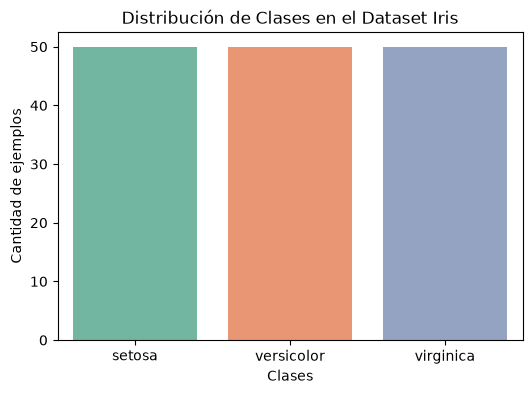

In [2]:
# 1. Carga del dataset Iris
iris = load_iris()

# 2. Convertir a un DataFrame de Pandas para mejor visualización
df_iris = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df_iris['target'] = iris.target
df_iris['target_name'] = df_iris['target'].map({0: iris.target_names[0], 
                                               1: iris.target_names[1], 
                                               2: iris.target_names[2]})

print("--- Información general ---")
print(f"Número de instancias (muestras): {iris.data.shape[0]}")
print(f"Número de características (features): {iris.data.shape[1]}")
print(f"Dimensiones de la matriz de características X: {iris.data.shape}")
print(f"Dimensiones del vector de etiquetas y: {iris.target.shape}")
print(f"Nombres de las características: {iris.feature_names}")
print(f"Clases disponibles: {iris.target_names}")
print("\nEjemplos por clase:")
print(df_iris['target_name'].value_counts())

# 3. Tabla con cinco ejemplos
print("\n--- Primeros 5 ejemplos del dataset ---")
display(df_iris.head())

# 4. Gráfico de distribución de clases
plt.figure(figsize=(6, 4))
sns.countplot(x='target_name', data=df_iris, palette='Set2')
plt.title('Distribución de Clases en el Dataset Iris')
plt.xlabel('Clases')
plt.ylabel('Cantidad de ejemplos')
plt.show()

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
    - Los modelos basados en distancias o de optimización por gradiente como Regresión Logística, SVM Lineal, K vecinos mas cercanos y perceptrón multicapa debido a que son sensibles a las escalas por lo que requieren de estandarización.

2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
    - Los modelos lineales generarán las fronteras de decisión de manera lineal y simple, mientras que los modelos de árboles de decisión producirán fronteras en bloques.
    
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?
    - El Teorema del No Free Lunch dicta que ningún algoritmo de optimización o de aprendizaje automático es universalmente superior a otro cuando se evalúa su rendimiento promedio sobre todos los problemas posibles, entonces los modelos dependerán de la naturaleza específica de la distribución de los datos.

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# Importación de los modelos solicitados
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

# 1. Carga y partición de datos (Entrenamiento, Validación y Prueba)
iris = load_iris()
X, y = iris.data, iris.target

# Dividimos primero en train+val (80%) y test (20%)
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Luego dividimos train+val en train (60% del total) y validación (20% del total)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val)

# 2. Escalamiento de características (Ajustado estrictamente con el conjunto de entrenamiento)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# 3. Diccionario de modelos iniciales
models = {
    "Gaussian Naive Bayes": GaussianNB(),
    "Regresión Logística": LogisticRegression(max_iter=200, random_state=42),
    "SVM Lineal": SVC(kernel='linear', random_state=42),
    "Árbol de Decisión": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "MLP (Red Neuronal)": MLPClassifier(hidden_layer_sizes=(10,), max_iter=500, random_state=42)
}

# 4. Evaluación inicial en validación para selección de hiperparámetros básicos
val_results = []
for name, model in models.items():
    # Usamos datos escalados para todos (los árboles no se ven afectados, pero es válido)
    model.fit(X_train_scaled, y_train)
    preds_val = model.predict(X_val_scaled)
    
    acc = accuracy_score(y_val, preds_val)
    f1 = f1_score(y_val, preds_val, average='macro')
    val_results.append({"Modelo": name, "Val Accuracy": acc, "Val F1 Macro": f1})

df_val_results = pd.DataFrame(val_results)
print("--- Resultados en Validación ---")
display(df_val_results)

# 5. Evaluación final en el conjunto de prueba (Test) con los modelos congelados
test_results = []
trained_models = {}

for name, model in models.items():
    # Reentrenamos con la unión de train y val (o mantenemos el entrenado, 
    # pero para la prueba final evaluamos el comportamiento general)
    model.fit(X_train_scaled, y_train) # Opcional: entrenar con train_val si se prefiere
    preds_test = model.predict(X_test_scaled)
    
    acc_test = accuracy_score(y_test, preds_test)
    f1_test = f1_score(y_test, preds_test, average='macro')
    
    # Capturamos hiperparámetros principales de forma sencilla
    params = str(model.get_params())
    
    test_results.append({
        "Modelo": name,
        "Transformación": "StandardScaler",
        "Hiperparámetros principales": params[:50] + "...",
        "Accuracy de prueba": round(acc_test, 4),
        "F1 macro de prueba": round(f1_test, 4)
    })
    trained_models[name] = model

df_test_results = pd.DataFrame(test_results)
print("\n--- Resultados Finales en Prueba (Test) ---")
display(df_test_results)

--- Resultados en Validación ---


d:\Carpeta Vid\Archivos\Universidad\7to Semestre\Recuperacion de la Informacion\Notebooks\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


,Modelo,Val Accuracy,Val F1 Macro
0,Gaussian Naive Bayes,0.933333,0.933333
1,Regresión Logística,0.933333,0.933333
2,SVM Lineal,0.933333,0.933333
3,Árbol de Decisión,0.933333,0.933333
4,Random Forest,0.933333,0.933333
5,Gradient Boosting,0.900000,0.899749
6,MLP (Red Neuronal),0.866667,0.865320



--- Resultados Finales en Prueba (Test) ---


d:\Carpeta Vid\Archivos\Universidad\7to Semestre\Recuperacion de la Informacion\Notebooks\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
0,Gaussian Naive Bayes,StandardScaler,"{'priors': None, 'var_smoothing': 1e-09}...",0.9333,0.9333
1,Regresión Logística,StandardScaler,"{'C': 1.0, 'class_weight': None, 'dual': False...",0.9333,0.9333
2,SVM Lineal,StandardScaler,"{'C': 1.0, 'break_ties': False, 'cache_size': ...",0.9333,0.9333
3,Árbol de Decisión,StandardScaler,"{'ccp_alpha': 0.0, 'class_weight': None, 'crit...",0.9333,0.9333
4,Random Forest,StandardScaler,"{'bootstrap': True, 'ccp_alpha': 0.0, 'class_w...",0.9333,0.9333
5,Gradient Boosting,StandardScaler,"{'ccp_alpha': 0.0, 'criterion': 'deprecated', ...",0.9667,0.9666
6,MLP (Red Neuronal),StandardScaler,"{'activation': 'relu', 'alpha': 0.0001, 'batch...",0.9000,0.8977


## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
    - El Gradient Boosting fue el que obtuvo el mejor resultado en el conjunto de prueba, alcanzando un 96.67% de accuracy y un F1 de 0.9666. Los demás modelos como Naive Bayes, Regresión Logística, SVM, Árboles y Random Forest empataron con un 93.33%.

2. ¿Cuál fue el modelo más sencillo de programar?
    - Todos se programan igual de fácil porque en la librería scikit-learn se usan con los mismos dos comandos como fit para entrenar y predict para adivinar. En cuanto a entender su funcionamiento por dentro, Naive Bayes o la Regresión Logística son los más simples.

3. ¿Accuracy y F1 macro cuentan la misma historia?
    - En este caso sí porque el dataset Iris tiene las clases perfectamente equilibradas como se vio en la interpretación de datos donde habian50 ejemplos de cada flor. Cuando las clases están balanceadas, el porcentaje de aciertos (accuracy) y el promedio equilibrado (F1 macro) dicen prácticamente lo mismo.

4. ¿Cuál es la diferencia entre las métricas macro y micro?
    - El promedio macro calcula el resultado para cada clase por separado y luego saca un promedio simple, dándole la misma importancia a todas las clases. 
    - El promedio micro junta todos los aciertos y errores globales de forma general lo que equivale al accuracy global en problemas multiclase.

5. ¿Qué aporta el MLP frente a un modelo lineal?
    - El Perceptrón Multicapa - MLP añade capas ocultas y funciones de activación no lineales, lo que le permite aprender patrones y formas geométricas complejas en los datos que un modelo lineal como la regresión logística básica que jamás podría resolver por estar limitado a trazar líneas rectas.


Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.
- Se puede ver exactamente qué características físicas como los pétalos o sépalos más largos/cortos de lo normal confunden al modelo, haciéndolo dudar entre una clase y otra muy parecida por ejemplo esto se ve entre versicolor y virginica.
- No se puede asegurar que el error se deba a un fallo absoluto del algoritmo también puede deberse a que la flor analizada tenga una mutación natural o características físicas atípicas que se salgan del promedio común de su especie.

# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

In [5]:
from sklearn.datasets import load_diabetes

# 1. Carga del dataset Diabetes
diabetes = load_diabetes()
X, y = diabetes.data, diabetes.target

print("--- Descripción del Dataset Diabetes ---")
print(f"Número de instancias (muestras): {X.shape[0]}")
print(f"Número de características: {X.shape[1]}")
print(f"Nombres de las características: {diabetes.feature_names}")
print(f"Qué representa (target): Una medida cuantitativa de la progresión de la enfermedad un año después del inicio.")

--- Descripción del Dataset Diabetes ---
Número de instancias (muestras): 442
Número de características: 10
Nombres de las características: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Qué representa (target): Una medida cuantitativa de la progresión de la enfermedad un año después del inicio.


## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.
- No, un modelo más flexible no siempre produce un menor error en datos nuevos. Eso se debe a que un modelo con demasiada flexibilidad tendría la capacidad de memorizar casi de manera perfecta los datos hasta posiblemente el ruido lo que nos daría como resultado un sobreajuste, a su vez, al ajustarse tanto al entrenamiento puede que el modelo pierde la capacidad de generalizary si yo quiero que se enfrente a datos nuevos o de prueba que no había visto antes, sus predicciones tenderan a fallar considerablemente lo que nos daría como resultado mas error en comparación con modelos mas equilibrados y menos complejos.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Importación de modelos de regresión
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

# 2. División de datos (Train 60%, Val 20%, Test 20%)
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=42)

# 3. Definición de modelos usando Pipelines
models = {
    "Regresión Lineal": Pipeline([('scaler', StandardScaler()), ('reg', LinearRegression())]),
    "Ridge": Pipeline([('scaler', StandardScaler()), ('reg', Ridge(alpha=1.0, random_state=42))]),
    "Lasso": Pipeline([('scaler', StandardScaler()), ('reg', Lasso(alpha=0.1, random_state=42))]),
    "kNN Regresión": Pipeline([('scaler', StandardScaler()), ('reg', KNeighborsRegressor(n_neighbors=5))]),
    "Árbol de Regresión": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "MLP Regresión": Pipeline([('scaler', StandardScaler()), ('reg', MLPRegressor(hidden_layer_sizes=(50,), max_iter=1000, random_state=42))])
}

# 4. Evaluación en el conjunto de prueba (Test)
regression_results = []
trained_reg_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    
    regression_results.append({
        "Modelo": name,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R²": round(r2, 4)
    })
    trained_reg_models[name] = model

df_reg_results = pd.DataFrame(regression_results)
print("\n--- Resultados de Regresión en Prueba ---")
display(df_reg_results)


--- Resultados de Regresión en Prueba ---


d:\Carpeta Vid\Archivos\Universidad\7to Semestre\Recuperacion de la Informacion\Notebooks\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Modelo,MAE,RMSE,R²
0,Regresión Lineal,42.9245,54.1564,0.4464
1,Ridge,42.9704,54.0309,0.4490
2,Lasso,42.9618,53.9743,0.4501
3,kNN Regresión,41.6719,54.1050,0.4475
4,Árbol de Regresión,65.2022,81.8957,-0.2659
5,Random Forest,44.5383,55.1186,0.4266
6,Gradient Boosting,44.5667,54.7913,0.4334
7,MLP Regresión,49.3619,62.9002,0.2532


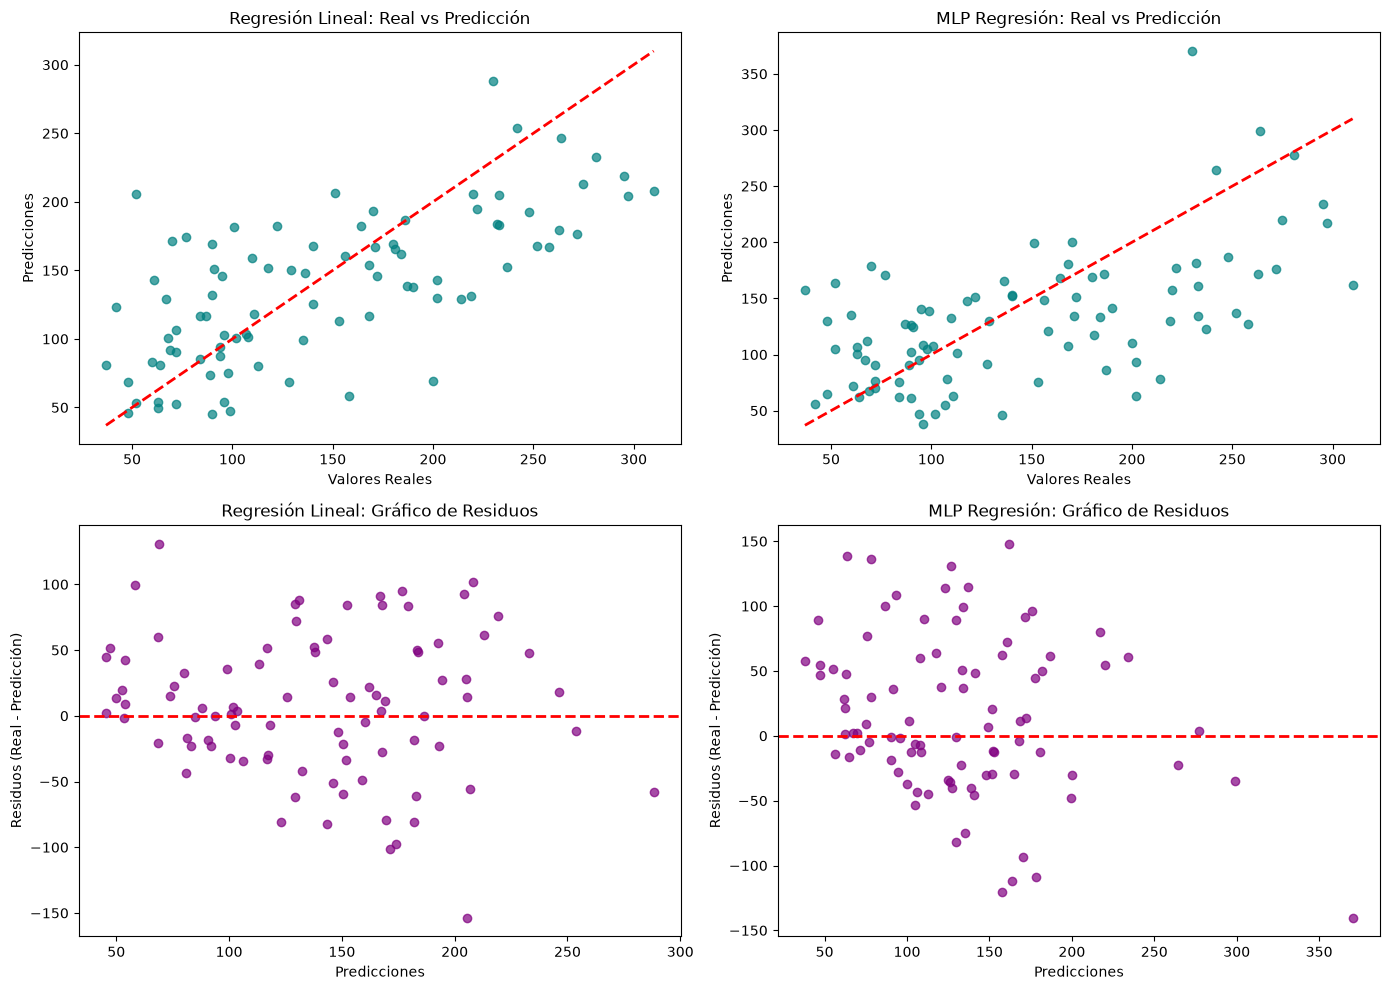


--- Dos ejemplos con errores absolutos grandes (Regresión Lineal) ---
Índice de prueba: 46 | Valor Real: 200.0 | Predicción: 68.97 | Error Absoluto: 131.03
Índice de prueba: 61 | Valor Real: 52.0 | Predicción: 205.66 | Error Absoluto: 153.66


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
reg_selected = ["Regresión Lineal", "MLP Regresión"]

for i, name in enumerate(reg_selected):
    model = trained_reg_models[name]
    preds = model.predict(X_test)
    residuals = y_test - preds
    
    # 1. Gráfico Real vs Predicciones
    axes[0, i].scatter(y_test, preds, alpha=0.7, color='teal')
    axes[0, i].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    axes[0, i].set_title(f'{name}: Real vs Predicción')
    axes[0, i].set_xlabel('Valores Reales')
    axes[0, i].set_ylabel('Predicciones')
    
    # 2. Gráfico de Residuos
    axes[1, i].scatter(preds, residuals, alpha=0.7, color='purple')
    axes[1, i].axhline(y=0, color='r', linestyle='--', lw=2)
    axes[1, i].set_title(f'{name}: Gráfico de Residuos')
    axes[1, i].set_xlabel('Predicciones')
    axes[1, i].set_ylabel('Residuos (Real - Predicción)')

plt.tight_layout()
plt.show()

# Identificar dos ejemplos con errores absolutos grandes en Regresión Lineal
lin_preds = trained_reg_models["Regresión Lineal"].predict(X_test)
abs_errors = np.abs(y_test - lin_preds)
worst_indices = np.argsort(abs_errors)[-2:] # Los 2 peores errores

print("\n--- Dos ejemplos con errores absolutos grandes (Regresión Lineal) ---")
for idx in worst_indices:
    print(f"Índice de prueba: {idx} | Valor Real: {y_test[idx]} | Predicción: {lin_preds[idx]:.2f} | Error Absoluto: {abs_errors[idx]:.2f}")

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
    - El modelo de Lasso obtuvo el mejor desempeño general con un $R^2$ de 0.4501 y el menor error cuadrático (RMSE de 53.97), seguido muy de cerca por Ridge y la Regresión Lineal. Por el contrario, los modelos más complejos como el Árbol de Regresión y el MLP tuvieron un rendimiento bajo o negativo.

2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
    - El Error Absoluto Medio (MAE) suma todos los errores dándoles el mismo peso mientras que el RMSE eleva al cuadrado los errores antes de promediarlos, lo que hace que castigue con mucha más fuerza los errores grandes. Un modelo con un error gigante aislado se verá mucho peor en RMSE que en MAE.

3. ¿Cómo se interpreta un R² negativo?
    - Significa que el modelo es peor que un modelo simple que se limitara a adivinar siempre el promedio de los datos reales esto ocurre cuando el modelo como el Árbol de Regresión que nos dio un valor de -0.2659 predice de forma desastrosa en el conjunto de prueba.

4. ¿Qué efecto tuvo aumentar la regularización?
    - Al aumentar la penalización, los coeficientes del modelo se reducen hacia cero. Esto ayuda a eliminar variables poco útiles, evita que el modelo memorice el ruido (overfitting) y vuelve al modelo más estable, aunque si se exagera puede empeorar el rendimiento.

5. ¿Qué puede explicar los errores grandes?
    - Ocurren porque hay casos particulares como el caso del índice 61, donde el valor real era 52 y el modelo predijo 205 que se salen por completo del comportamiento general de la mayoría de los pacientes, reflejando situaciones atípicas que el modelo no logra anticipar con las variables disponibles.

6. ¿Un coeficiente predictivo demuestra una relación causal?
    - No. Que un coeficiente sea alto solo indica que existe una asociación estadística o correlación matemática entre esa característica y la enfermedad, pero no demuestra que un cambio en dicha variable provoque directamente el cambio clínico.